# Assignment 15: k-Nearest Neighbors (k-NN) – Air Quality Classification

In this assignment I use the k-Nearest Neighbors (k-NN) algorithm to classify air quality. The dataset contains hourly readings from chemical sensors and reference analyzers in an Italian city. I create a binary target, CO_Level, that shows whether the carbon monoxide concentration, CO(GT), is above or below the median, and I predict it from the other sensor readings and weather measurements.

k-NN classifies a new reading by looking at the k most similar readings in the training data and taking a majority vote. It is distance-based, so feature scaling is important.

Steps I will follow:
1. Import libraries and load the data
2. Check the structure and clean the data (data types, missing values, duplicates)
3. Split the data into training and testing sets and create the target
4. Explore the training data (EDA)
5. Train k-NN for different values of k, with and without feature scaling
6. Find the optimal k with cross-validation
7. Evaluate with a confusion matrix and a classification report
8. Write a short report

## Step 1: Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

pd.set_option("display.max_columns", None)
random_seed = 42

## Step 2: Load the Dataset and Check Its Structure

In [2]:
air = pd.read_csv("AirQuality.csv", sep=";")

print("Shape:", air.shape)
display(air.head())
air.info()

Shape: (9471, 17)


,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,Unnamed: 15,Unnamed: 16
0,10/03/2004,18.00.00,"2,6",1360.0,150.0,"11,9",1046.0,166.0,1056.0,113.0,1692.0,1268.0,"13,6","48,9","0,7578",NaN,NaN
1,10/03/2004,19.00.00,2,1292.0,112.0,"9,4",955.0,103.0,1174.0,92.0,1559.0,972.0,"13,3","47,7","0,7255",NaN,NaN
2,10/03/2004,20.00.00,"2,2",1402.0,88.0,"9,0",939.0,131.0,1140.0,114.0,1555.0,1074.0,"11,9","54,0","0,7502",NaN,NaN
3,10/03/2004,21.00.00,"2,2",1376.0,80.0,"9,2",948.0,172.0,1092.0,122.0,1584.0,1203.0,"11,0","60,0","0,7867",NaN,NaN
4,10/03/2004,22.00.00,"1,6",1272.0,51.0,"6,5",836.0,131.0,1205.0,116.0,1490.0,1110.0,"11,2","59,6","0,7888",NaN,NaN


<class 'pandas.DataFrame'>
RangeIndex: 9471 entries, 0 to 9470
Data columns (total 17 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Date           9357 non-null   str    
 1   Time           9357 non-null   str    
 2   CO(GT)         9357 non-null   str    
 3   PT08.S1(CO)    9357 non-null   float64
 4   NMHC(GT)       9357 non-null   float64
 5   C6H6(GT)       9357 non-null   str    
 6   PT08.S2(NMHC)  9357 non-null   float64
 7   NOx(GT)        9357 non-null   float64
 8   PT08.S3(NOx)   9357 non-null   float64
 9   NO2(GT)        9357 non-null   float64
 10  PT08.S4(NO2)   9357 non-null   float64
 11  PT08.S5(O3)    9357 non-null   float64
 12  T              9357 non-null   str    
 13  RH             9357 non-null   str    
 14  AH             9357 non-null   str    
 15  Unnamed: 15    0 non-null      float64
 16  Unnamed: 16    0 non-null      float64
dtypes: float64(10), str(7)
memory usage: 1.6 MB


In [3]:
print("\nMissing values per column:\n", air.isnull().sum())
print("\nLast 3 rows:")
display(air.tail(3))


Missing values per column:
 Date              114
Time              114
CO(GT)            114
PT08.S1(CO)       114
NMHC(GT)          114
C6H6(GT)          114
PT08.S2(NMHC)     114
NOx(GT)           114
PT08.S3(NOx)      114
NO2(GT)           114
PT08.S4(NO2)      114
PT08.S5(O3)       114
T                 114
RH                114
AH                114
Unnamed: 15      9471
Unnamed: 16      9471
dtype: int64

Last 3 rows:


,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,Unnamed: 15,Unnamed: 16
9468,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9469,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9470,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Interpretation: Dataset Structure

The dataset has 9,471 rows and 17 columns. Each row is one hourly reading, with:
- Date and Time of the reading
- CO(GT), NMHC(GT), C6H6(GT), NOx(GT) and NO2(GT): true pollutant concentrations measured by a reference analyzer ("GT" means ground truth)
- PT08.S1 to PT08.S5: responses of 5 chemical sensors
- T (temperature), RH (relative humidity) and AH (absolute humidity)

I found three structural problems:
1. Unnamed: 15 and Unnamed: 16 are completely empty (9,471 missing values each). They are created by extra semicolons at the end of each line, so I will remove them.
2. 114 rows are completely empty (all values missing), including the last rows of the file. The real data has 9,357 rows.
3. CO(GT), C6H6(GT), T, RH and AH are stored as text instead of numbers, because they use a comma as the decimal point (for example "2,6" instead of 2.6). I need to replace the commas with dots and convert them to float.

The Date and Time columns will not be used as features.

## Step 3: Data Cleaning – Columns, Data Types and Missing Values

In [4]:
# 1. Remove empty columns and completely empty rows
air = air.drop(columns=["Unnamed: 15", "Unnamed: 16"])
air = air.dropna(how="all").reset_index(drop=True)
print("Shape after removing empty columns/rows:", air.shape)

Shape after removing empty columns/rows: (9357, 15)


In [5]:
# 2. Comma -> dot, then convert to float
comma_cols = ["CO(GT)", "C6H6(GT)", "T", "RH", "AH"]
for col in comma_cols:
    air[col] = air[col].str.replace(",", ".").astype(float)
print("\nData types after conversion:\n", air.dtypes.value_counts())
print("Missing values now:", air.isnull().sum().sum())


Data types after conversion:
 float64    13
str         2
Name: count, dtype: int64
Missing values now: 0


## Step 4: Detecting Hidden Missing Values


In [6]:
num_cols = air.columns.drop(["Date", "Time"])

In [7]:
# Evidence 1: summary statistics - look at the minimum of every column
summary = air[num_cols].describe().T[["min", "25%", "50%", "75%", "max"]]

In [8]:
# Evidence 2: the second-smallest value - is -200 far away from the rest of the data?
summary["2nd smallest"] = air[num_cols].apply(lambda s: s[s != s.min()].min())

In [9]:
# Evidence 3: how often does the minimum value appear?
summary["count of min"] = (air[num_cols] == air[num_cols].min()).sum()
print(summary.round(2).to_string())

                 min      25%      50%     75%      max  2nd smallest  count of min
CO(GT)        -200.0     0.60     1.50     2.6    11.90          0.10          1683
PT08.S1(CO)   -200.0   921.00  1053.00  1221.0  2040.00        647.00           366
NMHC(GT)      -200.0  -200.00  -200.00  -200.0  1189.00          7.00          8443
C6H6(GT)      -200.0     4.00     7.90    13.6    63.70          0.10           366
PT08.S2(NMHC) -200.0   711.00   895.00  1105.0  2214.00        383.00           366
NOx(GT)       -200.0    50.00   141.00   284.0  1479.00          2.00          1639
PT08.S3(NOx)  -200.0   637.00   794.00   960.0  2683.00        322.00           366
NO2(GT)       -200.0    53.00    96.00   133.0   340.00          2.00          1642
PT08.S4(NO2)  -200.0  1185.00  1446.00  1662.0  2775.00        551.00           366
PT08.S5(O3)   -200.0   700.00   942.00  1255.0  2523.00        221.00           366
T             -200.0    10.90    17.20    24.1    44.60         -1.90       

In [10]:
# Evidence 4: the most common value in each column
print("\nMost frequent value per column:")
print(air[num_cols].mode().iloc[0].to_string())


Most frequent value per column:
CO(GT)          -200.0
PT08.S1(CO)     -200.0
NMHC(GT)        -200.0
C6H6(GT)        -200.0
PT08.S2(NMHC)   -200.0
NOx(GT)         -200.0
PT08.S3(NOx)    -200.0
NO2(GT)         -200.0
PT08.S4(NO2)    -200.0
PT08.S5(O3)     -200.0
T               -200.0
RH              -200.0
AH              -200.0


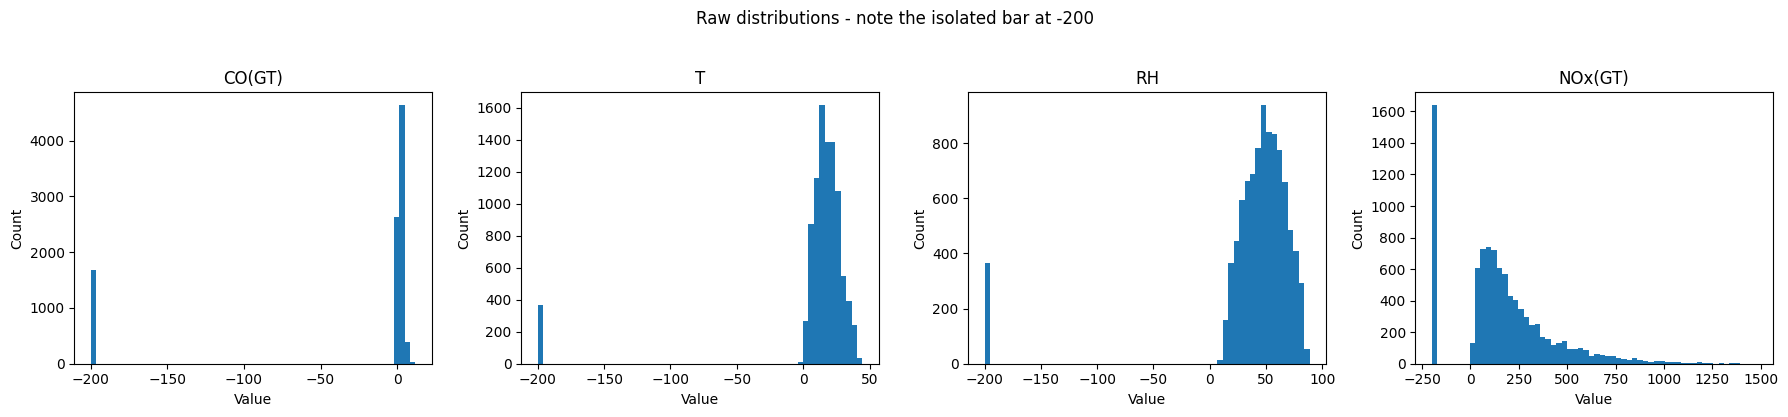

In [11]:
# Evidence 5: histograms - is -200 an isolated spike?
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, ["CO(GT)", "T", "RH", "NOx(GT)"]):
    ax.hist(air[col], bins=60)
    ax.set_title(col); ax.set_xlabel("Value"); ax.set_ylabel("Count")
plt.suptitle("Raw distributions - note the isolated bar at -200", y=1.03)
plt.tight_layout(); plt.show()

### Interpretation: Detecting Hidden Missing Values

After converting the data types, isnull() showed no missing values. But the summary statistics showed that every numeric column, including temperature, humidity, gas concentrations and sensor readings, has exactly the same minimum value: -200. Measurements of completely different things cannot all have the same minimum by coincidence.

The evidence that -200 is a missing-value code and not a real measurement:
1. Same minimum everywhere: all 13 numeric columns have a minimum of exactly -200.
2. A big gap: in the histograms, -200 appears as a separate bar, far to the left, with nothing between -200 and the real data, which starts around 0.
3. It appears too often to be an outlier: the -200 bar contains about 1,700 readings for CO(GT) and NOx(GT), and about 370 for T and RH. A real extreme value would appear only once or twice.
4. It is physically impossible:
   - CO and NOx concentrations cannot be negative.
   - Relative humidity (RH) must be between 0% and 100%.
   - A temperature of -200°C is impossible in an Italian city; the coldest temperature ever recorded on Earth is about -89°C.
5. The dataset documentation (UCI Machine Learning Repository) confirms that "missing values are tagged with -200 value".

So -200 means "missing". If I left it in the data, the model would treat it as a real value. For example, a CO(GT) of -200 would be labelled as "low CO", and k-NN distances would be distorted by these fake extreme values. In the next step I will replace -200 with NaN.

## Step 5: Handling Missing Values

In [13]:
# 1. Replace -200 with NaN
air[num_cols] = air[num_cols].replace(-200, np.nan)

missing_pct = (air.isnull().mean() * 100).round(1).sort_values(ascending=False)
print("Missing % per column:\n", missing_pct)

Missing % per column:
 NMHC(GT)         90.2
CO(GT)           18.0
NOx(GT)          17.5
NO2(GT)          17.5
PT08.S2(NMHC)     3.9
C6H6(GT)          3.9
PT08.S1(CO)       3.9
PT08.S5(O3)       3.9
T                 3.9
PT08.S3(NOx)      3.9
PT08.S4(NO2)      3.9
RH                3.9
AH                3.9
Date              0.0
Time              0.0
dtype: float64


In [14]:
# 2. Drop columns that are mostly missing (more than 50%)
mostly_missing = missing_pct[missing_pct > 50].index.tolist()
print("\nColumns dropped (>50% missing):", mostly_missing)
air = air.drop(columns=mostly_missing)


Columns dropped (>50% missing): ['NMHC(GT)']


In [15]:
# 3. Drop rows that still have missing values (as the instructions say)
before = len(air)
air = air.dropna().reset_index(drop=True)
print(f"Rows: {before} -> {len(air)} ({before - len(air)} removed, {(before - len(air)) / before:.1%})")

Rows: 9357 -> 6941 (2416 removed, 25.8%)


In [16]:
# 4. Duplicates
print("Duplicate rows:", air.duplicated().sum())
print("Final shape:", air.shape)
print("New minimum of CO(GT):", air["CO(GT)"].min(), "| T:", air["T"].min(), "| RH:", air["RH"].min())

Duplicate rows: 0
Final shape: (6941, 14)
New minimum of CO(GT): 0.1 | T: -1.9 | RH: 9.2


### Interpretation: Handling Missing Values

After replacing -200 with NaN, the real amount of missing data became visible:
- NMHC(GT) is missing 90.2% of the time, so I dropped this column. Keeping it would have forced me to delete almost all rows.
- CO(GT), NOx(GT) and NO2(GT) are missing about 17.5% to 18% of the time. These are measurements from the reference analyzers.
- All 5 chemical sensors (PT08.S1 to S5), C6H6(GT), T, RH and AH are each missing exactly 3.9%. The identical percentage suggests that the whole sensor device was offline at the same hours.

I then dropped all rows with missing values, as the instructions ask. This reduced the data from 9,357 to 6,941 rows (2,416 removed, 25.8%). It is a large loss, but 6,941 rows is still plenty for k-NN. I did not fill in (impute) the missing values, especially for CO(GT), because the target is created from it and imputing it would mean inventing the answers.

The minimum values are now realistic: CO(GT) 0.1, temperature -1.9°C and relative humidity 9.2%, which confirms that all -200 codes have been handled. There are no duplicate rows. The final dataset has 6,941 rows and 14 columns.

## Step 6: Split the Data and Create the Target Variable (CO_Level)

In [17]:
# Features: everything except Date, Time and CO(GT) (CO(GT) is only used to build the target)
X = air.drop(columns=["Date", "Time", "CO(GT)"])
co = air["CO(GT)"]

X_train, X_test, co_train, co_test = train_test_split(X, co, test_size=0.2, random_state=random_seed)


In [18]:
# Target: CO above the TRAINING median = 1 (high), otherwise 0 (low)
co_median = co_train.median()
y_train = (co_train > co_median).astype(int).rename("CO_Level")
y_test = (co_test > co_median).astype(int).rename("CO_Level")

print("Features used:", list(X.columns))
print("Train:", X_train.shape, "| Test:", X_test.shape)
print(f"\nCO(GT) median (train): {co_median} mg/m³")
print("Readings exactly equal to the median (train):", (co_train == co_median).sum())
print("\nCO_Level proportions (train):", y_train.value_counts(normalize=True).round(3).to_dict())
print("CO_Level proportions (test): ", y_test.value_counts(normalize=True).round(3).to_dict())

Features used: ['PT08.S1(CO)', 'C6H6(GT)', 'PT08.S2(NMHC)', 'NOx(GT)', 'PT08.S3(NOx)', 'NO2(GT)', 'PT08.S4(NO2)', 'PT08.S5(O3)', 'T', 'RH', 'AH']
Train: (5552, 11) | Test: (1389, 11)

CO(GT) median (train): 1.9 mg/m³
Readings exactly equal to the median (train): 168

CO_Level proportions (train): {0: 0.528, 1: 0.472}
CO_Level proportions (test):  {0: 0.514, 1: 0.486}


### Interpretation: Train/Test Split and Target Creation

I used 11 features: the 5 chemical sensor responses (PT08.S1 to S5), the reference measurements of C6H6, NOx and NO2, and the weather variables T, RH and AH. I removed CO(GT) from the features because the target is created from it. Keeping it would give the model the answer directly.

I split the data 80/20: 5,552 rows for training and 1,389 for testing. I created the target after the split, using the median of CO(GT) from the training data only (1.9 mg/m³), so the test data did not influence the threshold:
- CO_Level = 1 (high) if CO(GT) is above 1.9 mg/m³
- CO_Level = 0 (low) if CO(GT) is 1.9 mg/m³ or below

168 training readings are exactly 1.9, and they count as low. This is why the classes are not exactly 50/50: the training set is 52.8% low and 47.2% high, and the test set is 51.4% low and 48.6% high. The classes are well balanced, so accuracy is a fair main metric for this task.

## Step 7: Exploratory Data Analysis (Training Data Only)

In [19]:
train_df = X_train.copy()
train_df["CO_Level"] = y_train.values

# 1. Feature scales - important for k-NN
print("Feature summary (train):")
print(X_train.describe().T[["mean", "std", "min", "max"]].round(2).to_string())

Feature summary (train):
                  mean     std     min      max
PT08.S1(CO)    1119.03  220.08  647.00  2040.00
C6H6(GT)         10.53    7.52    0.20    63.70
PT08.S2(NMHC)   957.07  265.77  390.00  2214.00
NOx(GT)         252.44  211.96    2.00  1479.00
PT08.S3(NOx)    817.89  252.40  325.00  2683.00
NO2(GT)         114.13   47.80    3.00   333.00
PT08.S4(NO2)   1449.38  353.70  551.00  2775.00
PT08.S5(O3)    1057.32  410.00  221.00  2523.00
T                17.70    8.89   -1.90    44.60
RH               48.88   17.39    9.20    88.70
AH                0.98    0.40    0.19     2.18


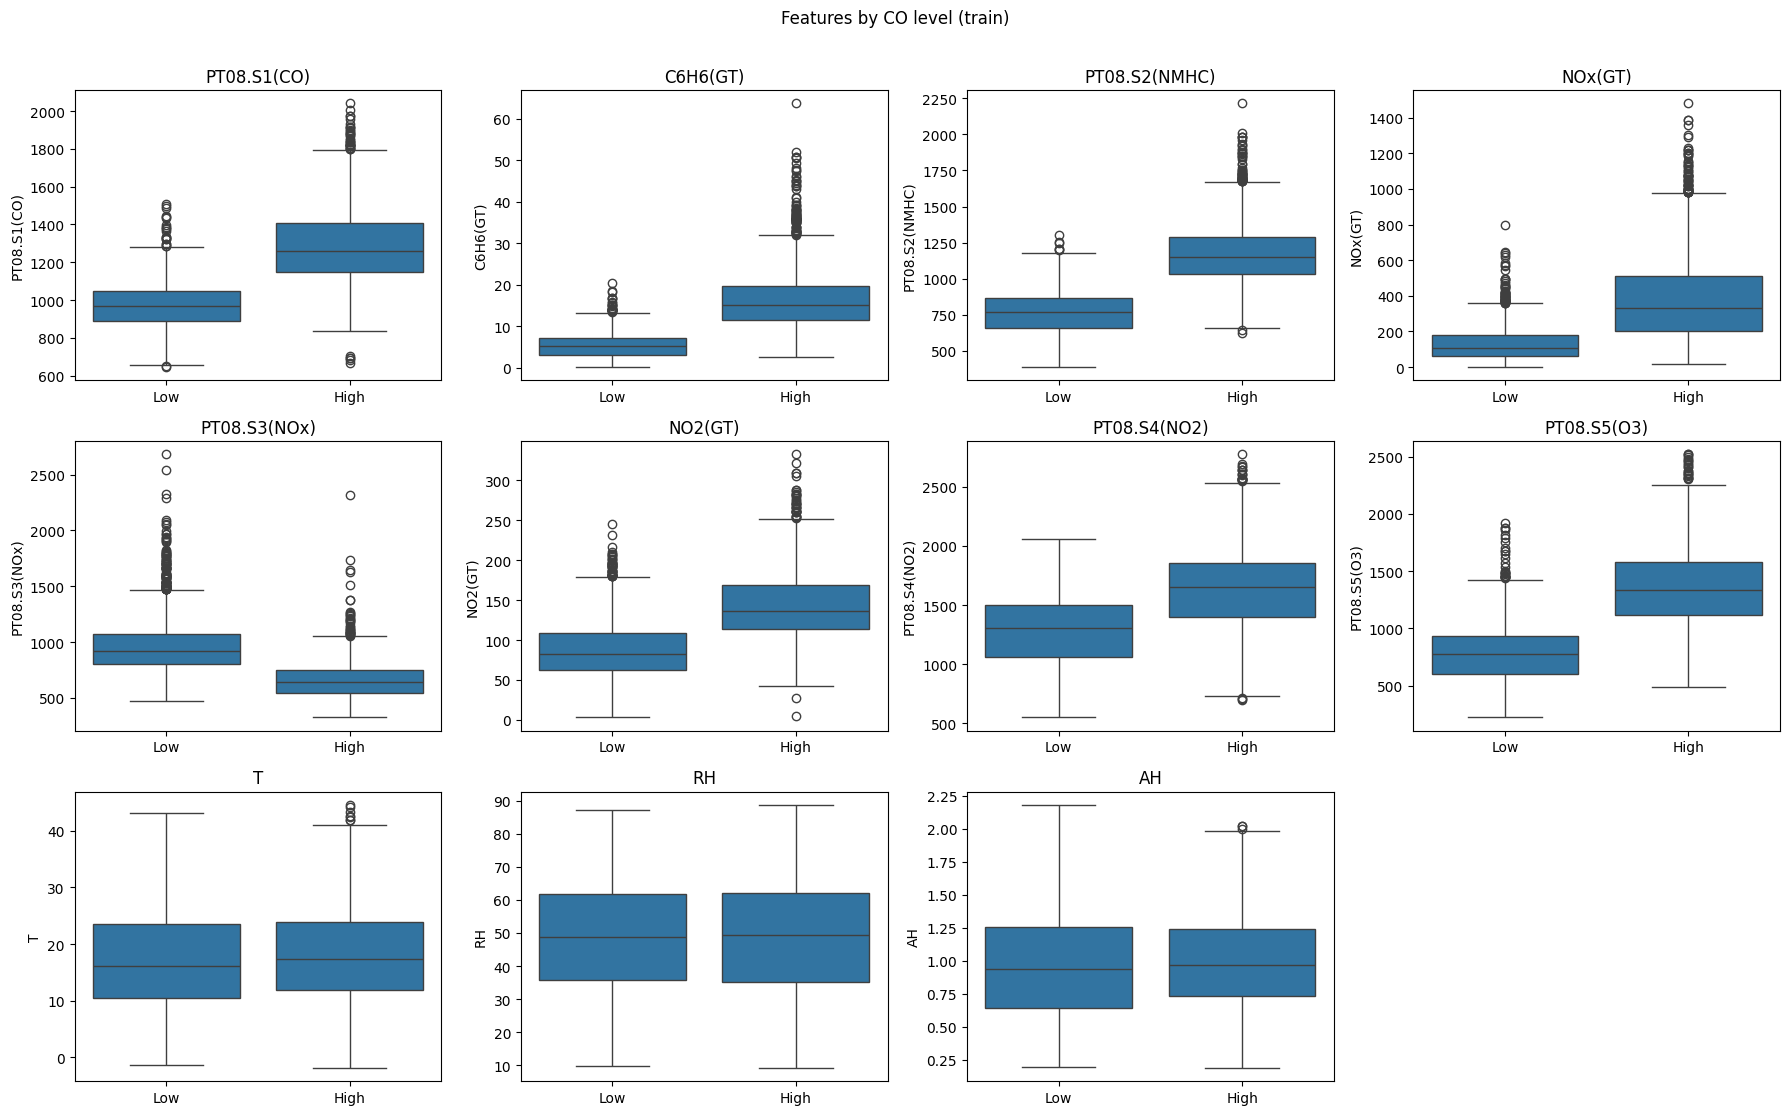

In [20]:
# 2. Boxplots: how each feature differs between low and high CO
fig, axes = plt.subplots(3, 4, figsize=(18, 11))
for ax, col in zip(axes.ravel(), X_train.columns):
    sns.boxplot(x="CO_Level", y=col, data=train_df, ax=ax)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Low", "High"]); ax.set_xlabel(""); ax.set_title(col)
axes.ravel()[-1].axis("off")
plt.suptitle("Features by CO level (train)", y=1.01); plt.tight_layout(); plt.show()


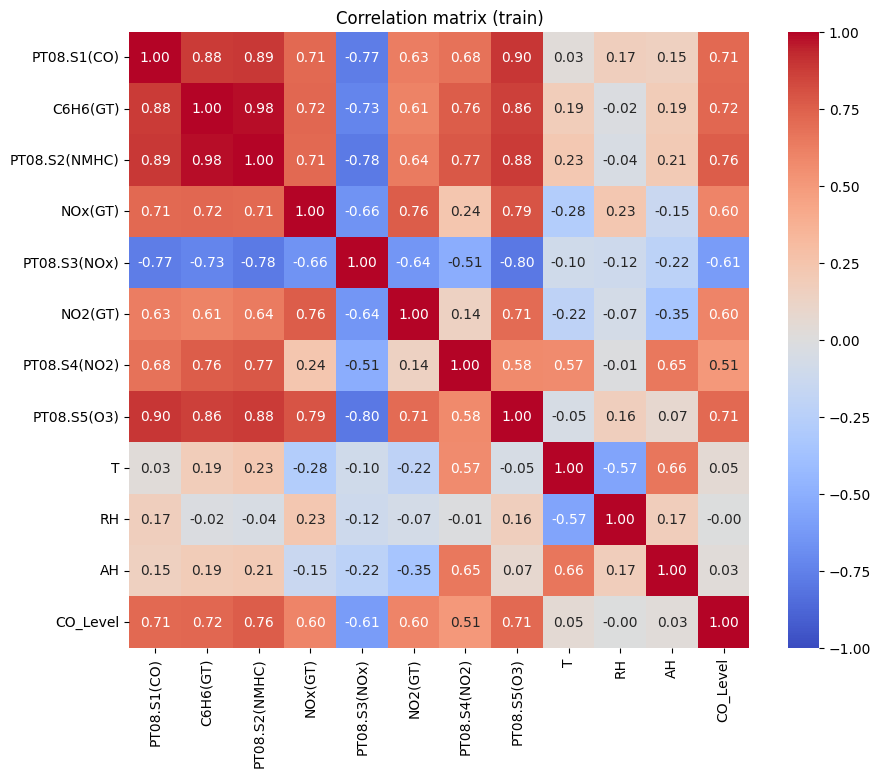

In [21]:
# 3. Correlation heatmap (features + target)
plt.figure(figsize=(10, 8))
sns.heatmap(train_df.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation matrix (train)"); plt.show()

In [22]:
print("Correlation with CO_Level:")
print(train_df.corr()["CO_Level"].drop("CO_Level").sort_values(key=abs, ascending=False).round(3))

Correlation with CO_Level:
PT08.S2(NMHC)    0.761
C6H6(GT)         0.723
PT08.S5(O3)      0.712
PT08.S1(CO)      0.711
PT08.S3(NOx)    -0.614
NOx(GT)          0.599
NO2(GT)          0.598
PT08.S4(NO2)     0.505
T                0.052
AH               0.030
RH              -0.001
Name: CO_Level, dtype: float64


### Interpretation: Exploratory Data Analysis

Feature scales:
The features are on very different scales. The sensor responses (PT08.S1 to S5) have values in the hundreds to thousands, with standard deviations between 220 and 410. Absolute humidity (AH) has a mean of 0.98 and a standard deviation of only 0.40. k-NN uses distances between points, so without scaling the large sensor features would dominate the distance and features like AH, T and NO2 would hardly count.

Relationship with the target:
Eight features are strongly related to CO_Level. PT08.S2(NMHC) has the strongest correlation (0.761), followed by C6H6(GT) (0.723), PT08.S5(O3) (0.712), PT08.S1(CO) (0.711), NOx(GT) (0.599), NO2(GT) (0.598) and PT08.S4(NO2) (0.505). In the boxplots, the high-CO group has clearly higher values for all of these. PT08.S3(NOx) is the exception, with a negative correlation (-0.614): its values are lower when CO is high, which means this sensor's reading drops as pollution rises. All of these features show a clear separation between low and high CO, so k-NN should be able to find meaningful neighbours.

The weather features are not related to CO_Level: T (0.052), AH (0.030) and RH (-0.001). Their boxplots look almost the same for both groups. For k-NN these features mostly add noise to the distance calculation.

Multicollinearity:
Many features are highly correlated with each other. C6H6(GT) and PT08.S2(NMHC) have a correlation of 0.98, and PT08.S1, PT08.S2, PT08.S5 and C6H6 are all correlated between 0.86 and 0.90. They largely measure the same pollution pattern. k-NN does not break because of this, but this information effectively gets counted several times in the distance.

Outliers:
Most pollution features have many high outliers in the high-CO group, such as C6H6 up to 63.7 and NOx up to 1,479. These are likely real high-pollution hours (for example rush hour or winter smog), so I keep them.

## Step 8: k-NN Classification – Accuracy for Different k (Without and With Feature Scaling)

In [23]:
k_values = range(1, 31)
accuracy_scores = []          # without scaling
accuracy_scores_scaled = []   # with StandardScaler

for k in k_values:
    # Without scaling
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train)
    y_pred = knn.predict(X_test)
    accuracy_scores.append(accuracy_score(y_test, y_pred))

    # With scaling
    knn_scaled = Pipeline([("scaler", StandardScaler()), ("knn", KNeighborsClassifier(n_neighbors=k))])
    knn_scaled.fit(X_train, y_train)
    y_pred_s = knn_scaled.predict(X_test)
    accuracy_scores_scaled.append(accuracy_score(y_test, y_pred_s))

    print(f"k = {k:2d} | Accuracy without scaling: {accuracy_scores[-1]:.4f} | with scaling: {accuracy_scores_scaled[-1]:.4f}")


k =  1 | Accuracy without scaling: 0.9158 | with scaling: 0.9266
k =  2 | Accuracy without scaling: 0.8985 | with scaling: 0.9122
k =  3 | Accuracy without scaling: 0.9266 | with scaling: 0.9294
k =  4 | Accuracy without scaling: 0.9165 | with scaling: 0.9237
k =  5 | Accuracy without scaling: 0.9266 | with scaling: 0.9280
k =  6 | Accuracy without scaling: 0.9208 | with scaling: 0.9266
k =  7 | Accuracy without scaling: 0.9280 | with scaling: 0.9316
k =  8 | Accuracy without scaling: 0.9258 | with scaling: 0.9287
k =  9 | Accuracy without scaling: 0.9302 | with scaling: 0.9330
k = 10 | Accuracy without scaling: 0.9280 | with scaling: 0.9323
k = 11 | Accuracy without scaling: 0.9316 | with scaling: 0.9323
k = 12 | Accuracy without scaling: 0.9316 | with scaling: 0.9330
k = 13 | Accuracy without scaling: 0.9266 | with scaling: 0.9302
k = 14 | Accuracy without scaling: 0.9316 | with scaling: 0.9302
k = 15 | Accuracy without scaling: 0.9323 | with scaling: 0.9316
k = 16 | Accuracy without

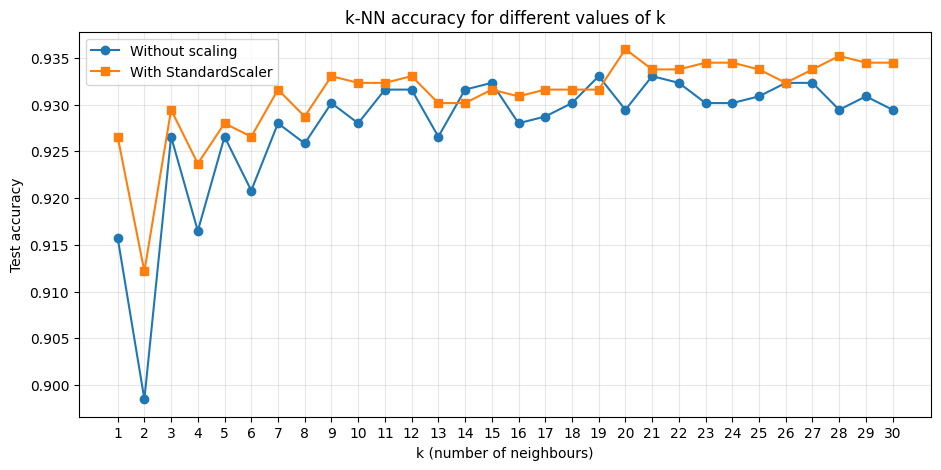


Best test accuracy without scaling: 0.9330 at k = 19
Best test accuracy with scaling:    0.9359 at k = 20


In [24]:
plt.figure(figsize=(11, 5))
plt.plot(k_values, accuracy_scores, marker="o", label="Without scaling")
plt.plot(k_values, accuracy_scores_scaled, marker="s", label="With StandardScaler")
plt.xlabel("k (number of neighbours)"); plt.ylabel("Test accuracy")
plt.title("k-NN accuracy for different values of k")
plt.xticks(k_values); plt.legend(); plt.grid(alpha=0.3); plt.show()

best_k_raw = k_values[int(np.argmax(accuracy_scores))]
best_k_sc = k_values[int(np.argmax(accuracy_scores_scaled))]
print(f"\nBest test accuracy without scaling: {max(accuracy_scores):.4f} at k = {best_k_raw}")
print(f"Best test accuracy with scaling:    {max(accuracy_scores_scaled):.4f} at k = {best_k_sc}")

### Interpretation: Accuracy for Different Values of k

I trained k-NN for k = 1 to 30, with and without StandardScaler, and measured accuracy on the test set.

Effect of k:
- With k = 1 and k = 2, accuracy is lowest (91.6% and 89.9% without scaling). With very few neighbours, the model copies individual noisy points, which is overfitting.
- Accuracy rises quickly up to about k = 9, then levels off between 93.0% and 93.6%.
- Even values of k (2, 4, 6, 8) are often lower than their odd neighbours. With an even k, the vote can end in a tie (for example 1 vs 1), so it is safer to use an odd k for a two-class problem.

Effect of scaling:
Scaling improved accuracy for 25 of the 30 values of k. The biggest gains were for small k: at k = 1, accuracy rose from 91.6% to 92.7%, and at k = 2, from 89.9% to 91.2%. The best test accuracy was 93.59% with scaling (k = 20) and 93.30% without scaling (k = 19).

The improvement from scaling is smaller than I expected given the very different feature scales. Without scaling, the distance is dominated by the sensor features, which have large values, and these are also the strongest predictors. The weather features T, RH and AH have small values and almost no relationship with CO_Level, so they are effectively ignored. Scaling gives every feature equal weight. That helps the useful small-scale features like C6H6 and NO2, but it also gives more weight to the uninformative weather features. These two effects partly cancel out.

From k = 9 onwards, the differences are very small. 0.1% of accuracy is only about 1.4 test rows, so the best k = 20 found on the test set is not clearly better than nearby values. Choosing k from the test set also means the test set is being used for tuning, so in the next step I choose k with cross-validation on the training data.

## Step 9: Finding the Optimal k with Cross-Validation (GridSearchCV)

In [25]:
knn_pipe = Pipeline([("scaler", StandardScaler()), ("knn", KNeighborsClassifier())])

param_grid = {
    "scaler": [StandardScaler(), "passthrough"],
    "knn__n_neighbors": list(range(1, 41)),
    "knn__weights": ["uniform", "distance"]
}

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=random_seed)
grid = GridSearchCV(knn_pipe, param_grid, scoring="accuracy", cv=cv5, n_jobs=-1, return_train_score=True)
grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print("Best CV accuracy:", round(grid.best_score_, 4))

cv_res = pd.DataFrame(grid.cv_results_)
cv_res["Scaling"] = np.where(cv_res["param_scaler"].astype(str) == "passthrough", "Without scaling", "With scaling")

print("\nBest CV accuracy for each combination:")
print(cv_res.groupby(["Scaling", "param_knn__weights"])["mean_test_score"].max().round(4).to_string())

Best parameters: {'knn__n_neighbors': 7, 'knn__weights': 'distance', 'scaler': StandardScaler()}
Best CV accuracy: 0.9325

Best CV accuracy for each combination:
Scaling          param_knn__weights
With scaling     distance              0.9325
                 uniform               0.9307
Without scaling  distance              0.9298
                 uniform               0.9289


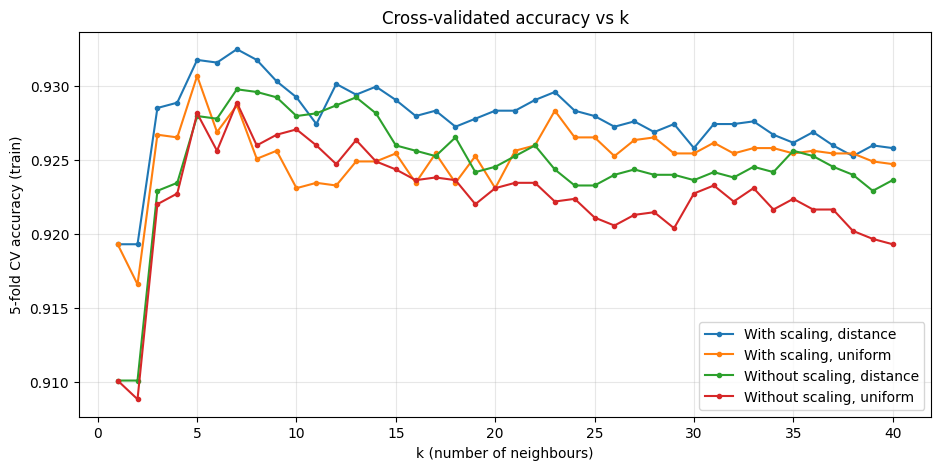

In [26]:
# CV accuracy vs k
plt.figure(figsize=(11, 5))
for (scaling, weights), grp in cv_res.groupby(["Scaling", "param_knn__weights"]):
    plt.plot(grp["param_knn__n_neighbors"], grp["mean_test_score"], marker=".", label=f"{scaling}, {weights}")
plt.xlabel("k (number of neighbours)"); plt.ylabel("5-fold CV accuracy (train)")
plt.title("Cross-validated accuracy vs k"); plt.legend(); plt.grid(alpha=0.3); plt.show()

### Interpretation: Finding the Optimal k with Cross-Validation

I used GridSearchCV with 5-fold cross-validation on the training data. I tested k from 1 to 40, two voting methods (uniform, where every neighbour has an equal vote, and distance, where closer neighbours count more), and two options: with and without StandardScaler. That is 160 combinations in total.

Best model:
The best combination was k = 7 with distance weighting and scaling, with a CV accuracy of 93.25%. The best k from cross-validation (7) is much smaller than the best k from the test set in Step 8 (20). This shows that choosing k from a single test set can be misleading, because the differences between values of k are very small and depend on which rows happen to be in the test set.

Effect of k:
In the chart, CV accuracy is lowest at k = 1 and 2 (overfitting), peaks between k = 5 and 7, and then slowly declines as k increases. With too many neighbours, the model averages over points that are less similar, which is underfitting.

Effect of scaling:
Scaling improved accuracy for both voting methods: from 92.98% to 93.25% with distance weighting, and from 92.89% to 93.07% with uniform weighting. In the chart, the scaled models stay above the unscaled models for most values of k, especially for k above 15. The improvement is small, for the same reason as in Step 8: the large-scale sensor features are also the most useful ones.

Effect of distance weighting:
Distance weighting was slightly better than uniform voting, and the difference grows with k. At k = 40, the unscaled uniform model drops to about 91.9%, while the scaled distance model stays around 92.6%. With distance weighting, faraway neighbours have less influence, so adding more neighbours does less harm.

Overall, the four approaches are within 0.4 percentage points of each other, so k-NN performs well on this dataset in all settings.

## Step 10: Final Model Evaluation – Confusion Matrix and Classification Report

Best model: {'knn__n_neighbors': 7, 'knn__weights': 'distance', 'scaler': StandardScaler()}
Test accuracy: 0.9330  (CV accuracy: 0.9325)

Classification report:
              precision    recall  f1-score   support

      Low CO       0.93      0.94      0.94       714
     High CO       0.93      0.93      0.93       675

    accuracy                           0.93      1389
   macro avg       0.93      0.93      0.93      1389
weighted avg       0.93      0.93      0.93      1389



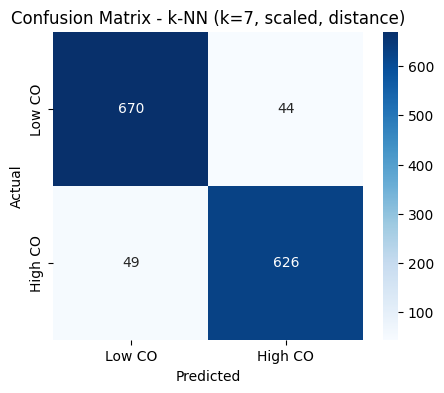

In [28]:
# 1. Best model (chosen by CV) - evaluated once on the test set
best_knn = grid.best_estimator_
y_pred_best = best_knn.predict(X_test)

print("Best model:", grid.best_params_)
print(f"Test accuracy: {accuracy_score(y_test, y_pred_best):.4f}  (CV accuracy: {grid.best_score_:.4f})")
print("\nClassification report:")
print(classification_report(y_test, y_pred_best, target_names=["Low CO", "High CO"]))

cm = confusion_matrix(y_test, y_pred_best)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Low CO", "High CO"], yticklabels=["Low CO", "High CO"])
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.title(f"Confusion Matrix - k-NN (k={grid.best_params_['knn__n_neighbors']}, scaled, distance)")
plt.show()

In [29]:
# 2. Impact of scaling on the test set: best unscaled model (also chosen by CV)
best_unscaled = cv_res[cv_res["Scaling"] == "Without scaling"].sort_values("rank_test_score").iloc[0]
knn_unscaled = KNeighborsClassifier(n_neighbors=int(best_unscaled["param_knn__n_neighbors"]),
                                    weights=best_unscaled["param_knn__weights"])
knn_unscaled.fit(X_train, y_train)
acc_unscaled = accuracy_score(y_test, knn_unscaled.predict(X_test))
print(f"Best unscaled model: k={int(best_unscaled['param_knn__n_neighbors'])}, "
      f"weights={best_unscaled['param_knn__weights']} -> test accuracy {acc_unscaled:.4f}")

Best unscaled model: k=7, weights=distance -> test accuracy 0.9266


In [30]:
# 3. Test our EDA idea: do the weather features (T, RH, AH) add noise?
X_train_noweather = X_train.drop(columns=["T", "RH", "AH"])
cv_all = cross_val_score(best_knn, X_train, y_train, cv=cv5).mean()
cv_noweather = cross_val_score(best_knn, X_train_noweather, y_train, cv=cv5).mean()
print(f"\nCV accuracy with all 11 features:        {cv_all:.4f}")
print(f"CV accuracy without T, RH, AH (8 features): {cv_noweather:.4f}")


CV accuracy with all 11 features:        0.9325
CV accuracy without T, RH, AH (8 features): 0.9317


The improvement from scaling is smaller than I expected given the very different feature scales. One likely reason is that the sensor features, which dominate the distance without scaling, are also the strongest predictors, so the unscaled model already focuses on the most useful information. (In Step 10 I tested whether the weather features add noise after scaling, and they do not.)

### Interpretation: Final Model Evaluation

Best model on the test set:
The best model from cross-validation (k = 7, distance weighting, with scaling) reached 93.30% accuracy on the test set, almost the same as its CV accuracy of 93.25%. This shows the cross-validation estimate was reliable and the model generalizes well to new data.

Confusion matrix:
- 670 of 714 low-CO hours were correctly classified (recall 0.94). 44 were wrongly predicted as high CO (false alarms).
- 626 of 675 high-CO hours were correctly classified (recall 0.93). 49 were missed and predicted as low CO.
- Precision is 0.93 for both classes, and F1 is 0.94 (low) and 0.93 (high).
The errors are well balanced between the two classes, so the model does not favour either one. Most errors are probably hours with CO close to the 1.9 mg/m³ median, where the difference between "low" and "high" is very small.

Impact of scaling on the test set:
The best unscaled model (also k = 7 with distance weighting, chosen by cross-validation) reached 92.66% test accuracy. Scaling improved this to 93.30%, an increase of 0.64 percentage points, or about 9 fewer wrong predictions out of 1,389. This confirms the cross-validation result: scaling helps k-NN, but the improvement is moderate on this dataset.

Weather features experiment:
In the EDA, T, RH and AH showed almost no correlation with CO_Level, so I tested whether removing them would help. CV accuracy without them was 93.17%, slightly lower than 93.25% with them, so the weather features do not hurt the model and may help a little. A likely reason is that gas sensor readings are affected by temperature and humidity. Even though these features do not predict CO directly, they help k-NN find neighbours that were measured under similar conditions. I kept all 11 features.

## Step 11: Report – k-NN on the Air Quality Dataset

### Overview
I used k-Nearest Neighbors (k-NN) to classify hourly air-quality readings as low or high carbon monoxide (CO_Level), based on whether CO(GT) was above the training median of 1.9 mg/m³. After cleaning, the dataset had 6,941 readings and 11 features (5 chemical sensors, C6H6, NOx and NO2 reference measurements, and temperature, relative humidity and absolute humidity). I split the data 80/20 (5,552 training rows, 1,389 test rows). The classes were well balanced (about 52% low / 48% high), so accuracy was a fair main metric.

### Performance of the model

| Model | k | Weights | CV accuracy | Test accuracy |
|---|---|---|---|---|
| k-NN without scaling | 7 | distance | 0.9298 | 0.9266 |
| **k-NN with StandardScaler** | **7** | **distance** | **0.9325** | **0.9330** |

### How well did k-NN perform?
k-NN performed very well. The final model (k = 7, distance weighting, with scaling) correctly classified 93.3% of test readings. Precision and recall were 0.93–0.94 for both classes, and the errors were balanced: 44 false alarms and 49 missed high-CO hours. The test accuracy matched the cross-validation accuracy (93.25%), so the result is reliable. The model works well because the sensor and pollutant features are strongly related to CO (correlations between 0.5 and 0.76), so readings with similar sensor values usually have similar CO levels. That is exactly the assumption k-NN relies on.

In the k experiments, very small k (1–2) gave the lowest accuracy because of overfitting. Accuracy peaked around k = 5–7 in cross-validation, and slowly declined for large k because of underfitting. Even values of k sometimes performed worse because of tied votes. Choosing k from the test set (k = 20) gave a different answer than cross-validation (k = 7), which shows why hyperparameters should be chosen with cross-validation on the training data.

### Impact of feature scaling
The features had very different scales: the sensor features ranged into the thousands (standard deviation 220–410), while absolute humidity had a standard deviation of only 0.40. k-NN is based on distance, so without scaling the large features dominate. Scaling with StandardScaler improved accuracy for most values of k, both on the test set (25 of 30 values of k in Step 8) and in cross-validation. The best model improved from 92.66% to 93.30% test accuracy. The improvement was moderate rather than dramatic, because the large-scale sensor features were also the most informative ones, so the unscaled model already focused on useful information. Scaling had the biggest effect at small k (up to +1.4 points) and at large k.

### Challenges faced
1. **Hidden missing values:** the dataset uses -200 as a missing-value code, so isnull() showed no missing values after conversion. I confirmed that -200 is not real by finding the same minimum of -200 in every column, a big gap to the next value, physically impossible values (negative concentrations, -200°C, negative humidity), very high counts, and the UCI documentation. If I had followed the instructions literally, about 18% of rows would have been labelled "low CO" because of a fake CO value of -200.
2. **Large data loss:** NMHC(GT) was 90.2% missing, so I dropped the column. Dropping rows with missing values still removed 25.8% of the data (9,357 to 6,941 rows).
3. **File format:** the data used semicolons as separators and commas as decimal points, had 2 empty columns, and had 114 empty rows, all of which needed cleaning before analysis.
4. **Target definition:** I calculated the median from the training data only, to avoid leakage. Because CO is recorded with 1 decimal place, 168 training readings were exactly at the median, so the classes were not exactly 50/50.
5. **Choosing k:** test-set accuracy changed by only about 0.1–0.6% across many values of k, so picking k from the test set was unreliable. Cross-validation gave a more stable choice.
6. **Time-series data:** the readings are hourly, and a random split puts neighbouring hours (which are very similar) in both the training and test sets. This probably makes the accuracy slightly optimistic. A time-based split (for example, training on earlier months and testing on later ones) would give a more realistic estimate.
7. **Computation:** k-NN stores all the training data and computes distances at prediction time, so the grid search (800 fits) was slower than for other models of this size.